In [1]:
# 1. Inladen en basisfuncties

#BLOK 1

from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Zoek een map met foto's, zonder ooit labels te openen.
opties = [Path("dataset/images"), Path("images"), Path(".")]
MAP = next((p for p in opties if p.is_dir() and any(p.glob("*.jpg"))), None)
if MAP is None:
    raise FileNotFoundError("Geen JPG-foto's gevonden. Pas MAP aan.")

fotos = sorted(p for p in MAP.glob("*.jpg")
               if "leeg_schaakbord" not in p.stem.lower()
               and not p.stem.lower().startswith("prev_"))
print(f"Map: {MAP.resolve()}")
print(f"Aantal afbeeldingen: {len(fotos)}")

# Foto's worden verkleind om de verwerking redelijk snel te houden.
MAX_DIM = 1500

def lees_foto(pad):
    img = cv2.imread(str(pad))
    if img is None:
        raise ValueError(f"Kan afbeelding niet laden: {pad}")
    h, w = img.shape[:2]
    factor = min(1.0, MAX_DIM / max(h, w))
    return cv2.resize(img, None, fx=factor, fy=factor)


#BLOK 2

def vind_zwarte_vakken(img):
    grijs = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    glad = cv2.GaussianBlur(grijs, (3, 3), 0)
    _, donker = cv2.threshold(
        glad, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )
    contouren, _ = cv2.findContours(
        donker, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE
    )
    kandidaten = []
    for contour in contouren:
        oppervlakte = cv2.contourArea(contour)
        if not 100 <= oppervlakte <= 6000:
            continue
        x, y, breedte, hoogte = cv2.boundingRect(contour)
        if min(breedte, hoogte) < 8:
            continue
        if max(breedte, hoogte) / min(breedte, hoogte) > 1.5:
            continue
        if oppervlakte / (breedte * hoogte) < 0.58:
            continue
        poly = cv2.approxPolyDP(
            contour, 0.065 * cv2.arcLength(contour, True), True
        )
        if not 4 <= len(poly) <= 6:
            continue
        # Een witte binnencontour telt niet als zwart vakje.
        cx = int(np.clip(x + breedte // 2, 0, grijs.shape[1] - 1))
        cy = int(np.clip(y + hoogte // 2, 0, grijs.shape[0] - 1))
        if donker[cy, cx] == 0:
            continue
        rechthoek = cv2.minAreaRect(contour)
        kandidaten.append((np.array(rechthoek[0]), oppervlakte, rechthoek))

    if len(kandidaten) < 6:
        raise ValueError("Te weinig zwarte vierkanten gevonden")
    oppervlaktes = np.array([c[1] for c in kandidaten])
    normaal = np.median(oppervlaktes)
    kandidaten = [c for c in kandidaten
                  if 0.55 * normaal < c[1] < 1.75 * normaal]
    if len(kandidaten) < 6:
        raise ValueError("Te weinig vierkanten met vergelijkbare grootte")
    return kandidaten


def pas_raster(kandidaten):
    posities = np.array([c[0] for c in kandidaten])
    vakgrootte = float(np.sqrt(np.median([c[1] for c in kandidaten])))

    # Een vierkant is bij 0 en 90 graden dezelfde vorm.
    hoeken = np.array([(c[2][2] + 45) % 90 - 45 for c in kandidaten])
    theta = np.deg2rad(float(np.median(hoeken)))
    u = vakgrootte * np.array([np.cos(theta), np.sin(theta)])
    v = vakgrootte * np.array([-np.sin(theta), np.cos(theta)])
    basis = np.column_stack([u, v])
    inverse = np.linalg.inv(basis)

    beste = None
    for anker in posities:
        indices = np.rint((posities - anker) @ inverse.T).astype(int)
        voorspeld = anker + indices @ basis.T
        fouten = np.linalg.norm(posities - voorspeld, axis=1)
        # Zwarte vakjes liggen op dezelfde pariteit van het schaakbord.
        inliers = ((fouten < 0.26 * vakgrootte)
                   & ((indices[:, 0] + indices[:, 1]) % 2 == 0))
        score = np.sum(inliers * (1 - np.minimum(fouten / vakgrootte, 1)))
        if beste is None or score > beste[0]:
            beste = (score, anker, indices, inliers)

    _, anker, indices, inliers = beste
    if inliers.sum() < 6:
        raise ValueError("Raster onbetrouwbaar: onvoldoende overeenkomende vakjes")

    # Kleine aanpassing van de rasterafstand en verschuiving.
    trans = np.array([anker, u, v], dtype=float)
    for _ in range(4):
        A = np.column_stack([np.ones(inliers.sum()), indices[inliers]])
        kandidaat_trans = np.linalg.lstsq(A, posities[inliers], rcond=None)[0]
        nu, nv = kandidaat_trans[1], kandidaat_trans[2]
        if not (0.80 * vakgrootte < np.linalg.norm(nu) < 1.20 * vakgrootte
                and 0.80 * vakgrootte < np.linalg.norm(nv) < 1.20 * vakgrootte):
            break
        basis_nieuw = np.column_stack([kandidaat_trans[1], kandidaat_trans[2]])
        indices_nieuw = np.rint(
            (posities - kandidaat_trans[0]) @ np.linalg.inv(basis_nieuw).T
        ).astype(int)
        fouten = np.linalg.norm(
            posities - (kandidaat_trans[0] + indices_nieuw @ basis_nieuw.T),
            axis=1
        )
        inliers_nieuw = ((fouten < 0.22 * vakgrootte)
                        & ((indices_nieuw[:, 0] + indices_nieuw[:, 1]) % 2 == 0))
        if inliers_nieuw.sum() < 6:
            break  # Houd vorige, betrouwbaardere schatting.
        trans, indices, inliers = kandidaat_trans, indices_nieuw, inliers_nieuw

    # Affiene projectie van rastercoördinaten naar de foto.
    M = np.array([[trans[1, 0], trans[2, 0], trans[0, 0]],
                  [trans[1, 1], trans[2, 1], trans[0, 1]],
                  [0., 0., 1.]], dtype=np.float64)

    return M, indices[inliers], inliers, vakgrootte


#BLOK 3

def selecteer_bord(img, kandidaten, M, vakgrootte):
    k = kandidaten
    v = vakgrootte
    h,w=img.shape[:2]
    centers=np.array([a[0] for a in k],dtype=np.float32)
    uv=cv2.perspectiveTransform(centers.reshape(-1,1,2),np.linalg.inv(M)).reshape(-1,2)
    ind=np.rint(uv).astype(int)
    reconstructed=cv2.perspectiveTransform(ind.reshape(-1,1,2).astype(np.float32),M).reshape(-1,2)
    err=np.linalg.norm(reconstructed-centers,axis=1)
    valid=(err < .28*v) & ((ind.sum(axis=1)%2)==0)
    inlier_idx=ind[valid]
    if len(inlier_idx)<8:raise ValueError('Minder dan 8 betrouwbare zwarte vakjes')
    gray=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
    variants=[]
    span=np.ptp(inlier_idx,axis=0)
    for cols,rows in [(8,11),(11,8)]:
       # all possible [x0..x0+cols-1] include a substantial portion of known candidates
       for x0 in range(int(inlier_idx[:,0].min()-cols+2),int(inlier_idx[:,0].max())):
        for y0 in range(int(inlier_idx[:,1].min()-rows+2),int(inlier_idx[:,1].max())):
         xi=np.arange(x0,x0+cols)
         yi=np.arange(y0,y0+rows)
         uu,vv=np.meshgrid(xi,yi)
         tilegrid=np.stack([uu.ravel(),vv.ravel()],axis=-1).astype('float32')
         pix=cv2.perspectiveTransform(tilegrid.reshape(-1,1,2),M).reshape(-1,2)
         xs=np.rint(pix[:,0]).astype(int);ys=np.rint(pix[:,1]).astype(int)
         inside=(xs>8)&(ys>8)&(xs<w-8)&(ys<h-8)
         if inside.mean()<.95:continue
         # check color polarization with global Otsu? detect dark squares vs white paper on board. use fixed medians from candidate black squares and nearby one-away whites
         patchvals=np.zeros(len(xs),float)
         for j0,(x,y) in enumerate(zip(xs,ys)):
          if inside[j0]:
           patchvals[j0]=np.median(gray[y-4:y+5,x-4:x+5])
         dark_expected=((tilegrid[:,0]+tilegrid[:,1])%2)==0
         black=patchvals[dark_expected&inside];white=patchvals[(~dark_expected)&inside]
         if len(black)<20 or len(white)<20:continue
         bc=np.median(black);wc=np.median(white)
         contrast=wc-bc
         if contrast<65:continue
         t=(bc+wc)/2
         correct=((dark_expected & (patchvals<t)) | ((~dark_expected)&(patchvals>=t))) & inside
         # robust standardized signed contrast + regularity
         score=np.mean(correct)*contrast + (correct.mean()-.5)*40
         # from inliers fraction in region
         within=((inlier_idx[:,0]>=x0)&(inlier_idx[:,0]<x0+cols)&(inlier_idx[:,1]>=y0)&(inlier_idx[:,1]<y0+rows))
         cnt=within.sum()
         score+=min(cnt,40)*.2
         variants.append((score,cols,rows,x0,y0,correct.mean(),contrast,cnt))
    if not variants:raise ValueError('Geen volledige bordregio met duidelijk zwart-wit patroon')
    result=max(variants)
    _,cols,rows,x0,y0,acc,contrast,cnt=result
    if acc<.79:raise ValueError(f'Schaakbordpatroon niet betrouwbaar ({acc:.0%} overeenstemming)')
    # refine H using known black squares WITHIN chosen region
    within=valid&(ind[:,0]>=x0)&(ind[:,0]<x0+cols)&(ind[:,1]>=y0)&(ind[:,1]<y0+rows)
    if within.sum()<8:raise ValueError('Te weinig punten binnen schaakbord')
    H,mask=cv2.findHomography(ind[within].astype(np.float32),centers[within],cv2.RANSAC,3.0)
    if H is None:raise ValueError('Homografie mislukt')
    meanerr=np.median(np.linalg.norm(cv2.perspectiveTransform(ind[within].reshape(-1,1,2).astype('float32'),H).reshape(-1,2)-centers[within],axis=1))
    return H,(cols,rows,x0,y0,acc,contrast,cnt,meanerr),inlier_idx


Map: C:\Users\Gkain\OneDrive\Documenten\PythonCrashCourse\computer vision\dataset\images
Aantal afbeeldingen: 240


In [2]:
# 2. Schaakbord zoeken en uitlijnen

# 4 — Schaakborddetectie met Hough en fijncorrectie
# Vereist: fotos en lees_foto() uit blok 1
# Geen labels, CNN of YOLO

from scipy.optimize import differential_evolution

CELL = 52
NX = 8
NY = 11


# 1. HOEKEN ORDENEN

def orden_hoeken(p):

    p = np.asarray(p, np.float32).reshape(4, 2)
    midden = p.mean(axis=0)

    hoeken = np.arctan2(
        p[:, 1] - midden[1],
        p[:, 0] - midden[0]
    )

    p = p[np.argsort(hoeken)]

    return np.roll(
        p, -int(np.argmin(p.sum(axis=1))), axis=0
    )


# 2. MOGELIJKE BORDCONTOUREN

def vind_bordcontour(img):

    H, W = img.shape[:2]
    schaal = min(1.0, 1100 / max(H, W))

    grijs = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    if schaal < 1:
        grijs = cv2.resize(
            grijs, None,
            fx=schaal,
            fy=schaal,
            interpolation=cv2.INTER_AREA
        )

    randen = cv2.Canny(
        cv2.GaussianBlur(grijs, (5, 5), 0),
        40, 110
    )

    randen = cv2.morphologyEx(
        randen,
        cv2.MORPH_CLOSE,
        np.ones((9, 9), np.uint8),
        iterations=2
    )

    contouren, _ = cv2.findContours(
        randen,
        cv2.RETR_LIST,
        cv2.CHAIN_APPROX_SIMPLE
    )

    h, w = grijs.shape
    gevonden = []

    for contour in contouren:

        oppervlakte = cv2.contourArea(contour)

        if not 0.03*h*w < oppervlakte < 0.8*h*w:
            continue

        omtrek = cv2.arcLength(contour, True)

        for eps in [0.015, 0.025, 0.04, 0.055]:

            vierhoek = cv2.approxPolyDP(
                contour, eps*omtrek, True
            )

            if (
                len(vierhoek) == 4
                and cv2.isContourConvex(vierhoek)
            ):
                break
        else:
            continue

        punten = orden_hoeken(vierhoek) / schaal

        zijden = np.linalg.norm(
            np.roll(punten, -1, axis=0) - punten,
            axis=1
        )

        a = np.mean(zijden[::2])
        b = np.mean(zijden[1::2])

        verhouding = min(a, b) / max(a, b)

        if not 0.48 < verhouding < 0.93:
            continue

        dubbel = any(
            np.mean(
                np.linalg.norm(punten - p, axis=1)
            ) < 15
            for p in gevonden
        )

        if not dubbel:
            gevonden.append(punten)

    if not gevonden:
        raise ValueError("Geen geschikte vierhoek gevonden")

    return sorted(
        gevonden,
        key=lambda p: -cv2.contourArea(p)
    )[:8]


# 3. VOORLOPIG SCHAAKBORD RECHTTREKKEN

def voorlopig_bord(img, punten):

    punten = orden_hoeken(punten)

    liggend = (
        np.linalg.norm(punten[1] - punten[0])
        >
        np.linalg.norm(punten[3] - punten[0])
    )

    W, H = (
        (NY*CELL, NX*CELL)
        if liggend
        else (NX*CELL, NY*CELL)
    )

    doel = np.float32([
        [0, 0],
        [W-1, 0],
        [W-1, H-1],
        [0, H-1]
    ])

    M = cv2.getPerspectiveTransform(punten, doel)

    if liggend:

        R = np.array([
            [0, -1, H-1],
            [1,  0, 0],
            [0,  0, 1]
        ], dtype=float)

        M = R @ M
        W, H = H, W

    bord = cv2.warpPerspective(
        img, M, (W, H)
    )

    return bord, M


# 4. REGELMATIGE HOUGH-LIJNEN FITTEN

def fit_rasteras(lijnen, aantal, afmeting):

    if len(lijnen) < 5:
        raise ValueError("Te weinig Hough-lijnen")

    z = np.asarray(lijnen, dtype=float)

    posities = z[:, 4]
    lengtes = z[:, 5]
    hellingen = z[:, 6]

    beste = None

    # Vakafstand en beginpositie zoeken
    for stap in np.arange(
        0.80*CELL, 1.25*CELL, 1.0
    ):

        for begin in np.arange(
            -0.9*CELL, 0.9*CELL, 2.5
        ):

            index = np.rint(
                (posities - begin) / stap
            ).astype(int)

            fout = np.abs(
                posities - (begin + index*stap)
            )

            geldig = (
                (index >= 0)
                & (index <= aantal)
                & (fout < 6)
            )

            nummers = np.unique(index[geldig])

            if len(nummers) < 4:
                continue

            if np.ptp(nummers) < max(
                3, int(aantal*0.4)
            ):
                continue

            steun = sum(
                min(
                    250,
                    lengtes[
                        geldig & (index == k)
                    ].sum()
                )
                for k in nummers
            )

            nauwkeurigheid = sum(
                np.mean(
                    np.exp(
                        -0.5 * (
                            fout[
                                geldig & (index == k)
                            ] / 3.5
                        )**2
                    )
                )
                for k in nummers
            )

            centrumfout = abs(
                begin + aantal*stap/2 - afmeting/2
            )

            score = (
                50*nauwkeurigheid
                + 0.25*steun
                + 70*len(nummers)
                - 1.5*centrumfout
            )

            if beste is None or score > beste[0]:
                beste = (score, begin, stap)

    if beste is None:
        raise ValueError("Geen regelmatig Hough-raster")

    _, begin, stap = beste

    # Vakafstand nauwkeuriger bepalen
    index = np.rint(
        (posities - begin) / stap
    ).astype(int)

    fout = np.abs(
        posities - (begin + index*stap)
    )

    geldig = (
        (index >= 0)
        & (index <= aantal)
        & (fout < 7)
    )

    nummers = np.unique(index[geldig])

    A = np.column_stack([
        np.ones(len(nummers)),
        nummers
    ])

    metingen = np.array([
        np.median(
            posities[geldig & (index == k)]
        )
        for k in nummers
    ])

    gewichten = np.array([
        np.sqrt(
            min(
                200,
                lengtes[geldig & (index == k)].sum()
            )
        )
        for k in nummers
    ])

    begin, stap = np.linalg.lstsq(
        A * gewichten[:, None],
        metingen * gewichten,
        rcond=None
    )[0]

    if not 0.76*CELL < stap < 1.30*CELL:
        raise ValueError("Onjuiste vakafstand")

    # Opnieuw groeperen
    index = np.rint(
        (posities - begin) / stap
    ).astype(int)

    fout = np.abs(
        posities - (begin + index*stap)
    )

    geldig = (
        (index >= 0)
        & (index <= aantal)
        & (fout < 7)
    )

    gemiddelde_helling = np.median(
        hellingen[geldig]
    )

    gevonden_lijnen = {}

    for k in np.unique(index[geldig]):

        selectie = (
            geldig
            & (index == k)
            & (
                np.abs(
                    hellingen - gemiddelde_helling
                ) < 0.12
            )
        )

        if not np.any(selectie):
            continue

        stukken = z[selectie]

        punten = np.vstack([
            stukken[:, 0:2],
            stukken[:, 2:4]
        ])

        if aantal == NX:
            onafhankelijk = punten[:, 1]
            afhankelijk = punten[:, 0]
        else:
            onafhankelijk = punten[:, 0]
            afhankelijk = punten[:, 1]

        if np.ptp(onafhankelijk) < 32:
            continue

        A = np.column_stack([
            np.ones(len(onafhankelijk)),
            onafhankelijk
        ])

        a, b = np.linalg.lstsq(
            A, afhankelijk, rcond=None
        )[0]

        if abs(b - gemiddelde_helling) < 0.14:
            gevonden_lijnen[int(k)] = (
                float(a), float(b)
            )

    if len(gevonden_lijnen) < 4:
        raise ValueError(
            "Onvoldoende betrouwbare rasterlijnen"
        )

    return gevonden_lijnen


# 5. PERSPECTIEFCORRECTIE MET RASTERLIJNEN

def verfijn_raster(img, hoeken):

    voorlopig, M = voorlopig_bord(img, hoeken)

    H, W = voorlopig.shape[:2]

    grijs = cv2.cvtColor(
        voorlopig, cv2.COLOR_BGR2GRAY
    )

    randen = cv2.Canny(
        cv2.GaussianBlur(grijs, (3, 3), 0),
        50, 130
    )

    lijnen = cv2.HoughLinesP(
        randen,
        rho=1,
        theta=np.pi/180,
        threshold=28,
        minLineLength=38,
        maxLineGap=12
    )

    if lijnen is None:
        raise ValueError("Geen Hough-lijnen gevonden")

    verticaal = []
    horizontaal = []

    for x1, y1, x2, y2 in lijnen.reshape(-1, 4):

        dx = x2 - x1
        dy = y2 - y1

        lengte = np.hypot(dx, dy)

        if abs(dx) < 0.24*abs(dy):

            helling = dx/dy

            positie = (
                (x1+x2)/2
                + helling*(H/2 - (y1+y2)/2)
            )

            verticaal.append([
                x1, y1, x2, y2,
                positie, lengte, helling
            ])

        elif abs(dy) < 0.24*abs(dx):

            helling = dy/dx

            positie = (
                (y1+y2)/2
                + helling*(W/2 - (x1+x2)/2)
            )

            horizontaal.append([
                x1, y1, x2, y2,
                positie, lengte, helling
            ])

    v_lijnen = fit_rasteras(
        verticaal, NX, W
    )

    h_lijnen = fit_rasteras(
        horizontaal, NY, H
    )

    # Snijpunten van de rasterlijnen
    bronpunten = []
    doelpunten = []

    for i, (a, b) in v_lijnen.items():

        for j, (c, d) in h_lijnen.items():

            matrix = np.array([
                [1, -b],
                [-d, 1]
            ], dtype=float)

            x, y = np.linalg.solve(
                matrix, [a, c]
            )

            if (
                -55 <= x < W+55
                and -55 <= y < H+55
            ):

                bronpunten.append([x, y])

                doelpunten.append([
                    i*CELL,
                    j*CELL
                ])

    if len(bronpunten) < 12:
        raise ValueError(
            "Te weinig rasterkruispunten"
        )

    # Perspectieftransformatie bepalen
    correctie, inliers = cv2.findHomography(
        np.float32(bronpunten),
        np.float32(doelpunten),
        cv2.RANSAC,
        6.0
    )

    if (
        correctie is None
        or inliers is None
        or np.mean(inliers) < 0.48
    ):
        raise ValueError("Onbetrouwbare rasterfit")

    H_nieuw = correctie @ M

    breedte = NX*CELL
    hoogte = NY*CELL

    bord = cv2.warpPerspective(
        img,
        H_nieuw,
        (breedte, hoogte)
    )

    # Controle van zwart-witcontrast
    grijs = cv2.cvtColor(
        bord, cv2.COLOR_BGR2GRAY
    )

    yy, xx = np.indices((NY, NX))

    even = (
        (xx + yy).ravel() % 2 == 0
    )

    cx = ((xx + 0.5)*CELL).astype(int).ravel()
    cy = ((yy + 0.5)*CELL).astype(int).ravel()

    waarden = grijs[cy, cx]

    contrast = abs(
        float(np.median(waarden[even]))
        - float(np.median(waarden[~even]))
    )

    if contrast < 35:
        raise ValueError(
            "Schaakbordcontrast onvoldoende"
        )

    # Randuitlijning controleren
    gx = np.abs(
        cv2.Sobel(
            grijs, cv2.CV_32F,
            1, 0, ksize=3
        )
    )

    gy = np.abs(
        cv2.Sobel(
            grijs, cv2.CV_32F,
            0, 1, ksize=3
        )
    )

    scores = []

    for i in range(1, NX):

        x = i*CELL

        rand = np.median(
            np.max(gx[:, x-2:x+3], axis=1)
        )

        naast = np.median(
            np.max(gx[:, x+12:x+17], axis=1)
        )

        scores.append(rand/(naast+1))

    for j in range(1, NY):

        y = j*CELL

        rand = np.median(
            np.max(gy[y-2:y+3, :], axis=0)
        )

        naast = np.median(
            np.max(gy[y+12:y+17, :], axis=0)
        )

        scores.append(rand/(naast+1))

    raster_score = float(np.median(scores))

    if raster_score < 1.45:
        raise ValueError(
            "Rasterlijnen onvoldoende uitgelijnd"
        )

    # Hoeken terug naar de originele foto
    doelhoeken = np.float32([
        [0, 0],
        [breedte-1, 0],
        [breedte-1, hoogte-1],
        [0, hoogte-1]
    ]).reshape(-1, 1, 2)

    hoeken_nieuw = cv2.perspectiveTransform(
        doelhoeken,
        np.linalg.inv(H_nieuw)
    ).reshape(4, 2)

    return bord, hoeken_nieuw, raster_score


# 6. FIJNCORRECTIE OP SCHAAKBORDPATROON

def optimaliseer_schaakbord(img, bord, hoeken):

    H, W = bord.shape[:2]

    grijs = cv2.cvtColor(
        bord, cv2.COLOR_BGR2GRAY
    ).astype(np.float32)

    gx = cv2.GaussianBlur(
        np.abs(cv2.Sobel(
            grijs, cv2.CV_32F,
            1, 0, ksize=3
        )),
        (0, 0), 1.8
    )

    gy = cv2.GaussianBlur(
        np.abs(cv2.Sobel(
            grijs, cv2.CV_32F,
            0, 1, ksize=3
        )),
        (0, 0), 1.8
    )

    norm_x = max(
        float(np.percentile(gx, 94)), 20
    )

    norm_y = max(
        float(np.percentile(gy, 94)), 20
    )

    # Meetpunten op de verwachte rasterlijnen
    fracties = np.array([0.22, 0.50, 0.78])

    xv = np.repeat(
        np.arange(1, NX)*CELL,
        NY*len(fracties)
    ).astype(float)

    yv = np.tile(
        (
            (np.arange(NY)[:, None] + fracties)
            * CELL
        ).ravel(),
        NX-1
    )

    yh = np.repeat(
        np.arange(1, NY)*CELL,
        NX*len(fracties)
    ).astype(float)

    xh = np.tile(
        (
            (np.arange(NX)[:, None] + fracties)
            * CELL
        ).ravel(),
        NY-1
    )

    yy, xx = np.indices((NY, NX))

    midden_x = (xx.ravel()+0.5)*CELL
    midden_y = (yy.ravel()+0.5)*CELL

    even = (
        (xx.ravel()+yy.ravel()) % 2 == 0
    )

    # Coördinaten transformeren
    def transformeer(x, y, p):

        dx, dy, sx, sy, hx, hy = p

        X = x-W/2
        Y = y-H/2

        nieuw_x = (
            W/2 + (1+sx)*X + hx*Y + dx
        )

        nieuw_y = (
            H/2 + hy*X + (1+sy)*Y + dy
        )

        return nieuw_x, nieuw_y

    # Pixelwaarden interpoleren
    def meet(beeld, x, y):

        return cv2.remap(
            beeld,
            np.asarray(
                x, np.float32
            ).reshape(1, -1),
            np.asarray(
                y, np.float32
            ).reshape(1, -1),
            cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT
        ).ravel()

    # Kwaliteit van de uitlijning
    def kwaliteit(p):

        X, Y = transformeer(xv, yv, p)
        rand_v = meet(gx, X, Y)/norm_x

        X, Y = transformeer(xv+12, yv, p)
        naast_v = meet(gx, X, Y)/norm_x

        X, Y = transformeer(xh, yh, p)
        rand_h = meet(gy, X, Y)/norm_y

        X, Y = transformeer(xh, yh+12, p)
        naast_h = meet(gy, X, Y)/norm_y

        score_randen = 0.5 * (
            np.mean(
                np.clip(rand_v, 0, 1.7)
                - 0.6*np.clip(naast_v, 0, 1.7)
            )
            +
            np.mean(
                np.clip(rand_h, 0, 1.7)
                - 0.6*np.clip(naast_h, 0, 1.7)
            )
        )

        X, Y = transformeer(
            midden_x, midden_y, p
        )

        waarden = meet(grijs, X, Y)

        zwart = waarden[even]
        wit = waarden[~even]

        contrast = abs(
            float(np.median(zwart))
            - float(np.median(wit))
        )

        score_kleur = np.clip(
            contrast/155, 0, 1.5
        )

        dx, dy, sx, sy, hx, hy = p

        straf = (
            0.08 * (
                (dx/15)**2 + (dy/15)**2
            )
            +
            0.15 * (
                (sx/0.05)**2
                + (sy/0.05)**2
                + (hx/0.05)**2
                + (hy/0.05)**2
            )
        )

        return float(
            score_randen
            + 0.35*score_kleur
            - straf
        )

    # Optimalisatie
    nul = np.zeros(6)
    score_voor = kwaliteit(nul)

    grenzen = [
        (-16, 16),
        (-16, 16),
        (-0.045, 0.045),
        (-0.045, 0.045),
        (-0.045, 0.045),
        (-0.045, 0.045)
    ]

    fit = differential_evolution(
        lambda p: -kwaliteit(p),
        grenzen,
        maxiter=25,
        popsize=7,
        seed=12,
        polish=True
    )

    p = fit.x
    score_na = kwaliteit(p)

    # Alleen een duidelijke verbetering accepteren
    if score_na-score_voor < 0.10:
        return (
            bord, hoeken,
            score_voor, score_na, False
        )

    dx, dy, sx, sy, hx, hy = p

    T = np.array([
        [
            1+sx, hx,
            dx-sx*W/2-hx*H/2
        ],
        [
            hy, 1+sy,
            dy-hy*W/2-sy*H/2
        ],
        [0, 0, 1]
    ], dtype=float)

    doel = np.float32([
        [0, 0],
        [W-1, 0],
        [W-1, H-1],
        [0, H-1]
    ])

    H_oud = cv2.getPerspectiveTransform(
        np.asarray(
            hoeken, np.float32
        ).reshape(4, 2),
        doel
    )

    H_nieuw = np.linalg.inv(T) @ H_oud

    # Dekking van de originele foto controleren
    dekking = cv2.warpPerspective(
        np.ones(
            img.shape[:2], np.uint8
        ),
        H_nieuw,
        (W, H)
    )

    if np.mean(dekking > 0) < 0.96:
        return (
            bord, hoeken,
            score_voor, score_na, False
        )

    bord_nieuw = cv2.warpPerspective(
        img,
        H_nieuw,
        (W, H)
    )

    hoeken_nieuw = cv2.perspectiveTransform(
        doel.reshape(-1, 1, 2),
        np.linalg.inv(H_nieuw)
    ).reshape(4, 2)

    return (
        bord_nieuw,
        hoeken_nieuw,
        score_voor,
        score_na,
        True
    )


# 7. COMPLETE SCHAAKBORDDETECTIE


In [3]:
# 3. GrabCut en schaakborddetectie

#BLOK 5 

def verfijn_met_grabcut(bord, zaad, score, cell=52):
    h,w=zaad.shape
    seed=(zaad>0).astype(np.uint8)*255
    kern=lambda n:cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(n,n))
    grouped=cv2.dilate(seed,kern(23),iterations=1)
    n,labels,stats,_=cv2.connectedComponentsWithStats(grouped,8)
    resultaat=np.zeros_like(seed)
    reports=[]
    for i in range(1,n):
        gx,gy,gw,gh,ga=map(int,stats[i])
        basis=np.zeros_like(seed)
        basis[labels==i]=seed[labels==i]
        if cv2.countNonZero(basis)<18:continue
        # skip long board-edge artifacts, giant merged regions
        if ga>0.20*h*w:continue
        # bounding of region + 1 tile extra context
        margin=max(20,int(0.65*cell))
        xa=max(0,gx-margin);ya=max(0,gy-margin)
        xb=min(w,gx+gw+margin);yb=min(h,gy+gh+margin)
        cut=bord[ya:yb,xa:xb]
        sh,sw=cut.shape[:2]
        seeds=basis[ya:yb,xa:xb]
        scorecut=score[ya:yb,xa:xb]
        definite=cv2.erode(seeds,kern(3),iterations=1)
        if cv2.countNonZero(definite)<5: definite=seeds
        # initialize with probable foreground around core only
        gc=np.full((sh,sw),cv2.GC_PR_BGD,np.uint8)
        probable=cv2.dilate(seeds,kern(31),iterations=1)
        gc[(probable>0) & (scorecut>12)]=cv2.GC_PR_FGD
        gc[definite>0]=cv2.GC_FGD
        # background from far away and ROI border
        far=cv2.dilate(probable,kern(25),iterations=1)==0
        gc[far]=cv2.GC_BGD
        gc[:3,:]=cv2.GC_BGD; gc[-3:,:]=cv2.GC_BGD
        gc[:,:3]=cv2.GC_BGD; gc[:,-3:]=cv2.GC_BGD
        if not (np.any(gc==cv2.GC_BGD) and np.any(gc==cv2.GC_FGD)):continue
        try:
            bg=np.zeros((1,65),np.float64);fg=np.zeros((1,65),np.float64)
            cv2.grabCut(cut,gc,None,bg,fg,4,cv2.GC_INIT_WITH_MASK)
        except cv2.error:continue
        mask=np.uint8((gc==cv2.GC_FGD)|(gc==cv2.GC_PR_FGD))*255
        mask=cv2.morphologyEx(mask,cv2.MORPH_OPEN,kern(3))
        mask=cv2.morphologyEx(mask,cv2.MORPH_CLOSE,kern(7))
        nc,lab,st,_=cv2.connectedComponentsWithStats(mask,8)
        for j in range(1,nc):
            ymask=(lab==j)
            overlap=np.count_nonzero(ymask & (seeds>0))
            if overlap<max(8,0.12*cv2.countNonZero(seeds)):
                continue
            if st[j,cv2.CC_STAT_AREA] > 0.65*sh*sw:continue
            # enforce original solid area stays inside
            result=mask[ymask] if False else None
            patch=resultaat[ya:yb,xa:xb]
            patch[ymask]=255
            reports.append((i,j,overlap,st[j,cv2.CC_STAT_AREA]))
    return resultaat,reports


def vind_bord_sb(img, cell=52):

    grijs = cv2.cvtColor(
        img, cv2.COLOR_BGR2GRAY
    )

    # ==========================================
    # 1. VERSCHILLENDE VOORBEWERKINGEN
    # ==========================================

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    contrast = clahe.apply(grijs)

    # Verschillende beeldversies proberen
    varianten = [
        (grijs, 1.0, "Origineel"),
        (contrast, 1.0, "CLAHE")
    ]

    # Verkleinde versie toevoegen bij grote foto's
    max_zijde = max(grijs.shape)

    if max_zijde > 1600:

        schaal = 1600 / max_zijde

        klein = cv2.resize(
            grijs,
            None,
            fx=schaal,
            fy=schaal,
            interpolation=cv2.INTER_AREA
        )

        klein_contrast = clahe.apply(klein)

        varianten.extend([
            (klein, schaal, "Verkleind"),
            (klein_contrast, schaal, "Verkleind + CLAHE")
        ])

    # ==========================================
    # 2. SCHAAKBORDHOEKEN ZOEKEN
    # ==========================================

    for afbeelding, schaal, naam in varianten:

        for cols, rows in [(7, 10), (10, 7)]:

            gevonden, hoeken = cv2.findChessboardCornersSB(
                afbeelding,
                (cols, rows),
                flags=cv2.CALIB_CB_EXHAUSTIVE
            )

            if not gevonden:
                continue

            # Punten naar originele foto terugrekenen
            bron = (
                hoeken.reshape(-1, 2) / schaal
            ).astype(np.float32)

            doel = np.float32([
                [(x + 1) * cell, (y + 1) * cell]
                for y in range(rows)
                for x in range(cols)
            ])

            # ==================================
            # 3. PERSPECTIEFCORRECTIE
            # ==================================

            H, inliers = cv2.findHomography(
                bron,
                doel,
                cv2.RANSAC,
                3.0
            )

            if H is None or inliers is None:
                continue

            betrouwbaarheid = float(np.mean(inliers))

            if betrouwbaarheid < 0.85:
                continue

            breedte = (cols + 1) * cell
            hoogte = (rows + 1) * cell

            # ==================================
            # 4. CONTROLE OP GELDIGE PIXELS
            # ==================================

            dekking = cv2.warpPerspective(
                np.full(grijs.shape, 255, dtype=np.uint8),
                H,
                (breedte, hoogte)
            )

            if np.mean(dekking > 0) < 0.95:
                continue

            bord = cv2.warpPerspective(
                img,
                H,
                (breedte, hoogte)
            )

            # Controleer het gevonden raster:
            # zwarte en witte vakjes moeten
            # afwisselende helderheden hebben.
            bord_grijs = cv2.cvtColor(
                bord, cv2.COLOR_BGR2GRAY
            )

            waarden = []

            for y in range(rows + 1):
                for x in range(cols + 1):

                    cx = int((x + 0.5) * cell)
                    cy = int((y + 0.5) * cell)

                    waarde = bord_grijs[cy, cx]

                    waarden.append((
                        (x + y) % 2,
                        float(waarde)
                    ))

            even = [v for p, v in waarden if p == 0]
            oneven = [v for p, v in waarden if p == 1]

            contrast_raster = abs(
                np.median(even) - np.median(oneven)
            )

            if contrast_raster < 25:
                continue

            print(
                f"ChessboardCornersSB: {naam}, "
                f"{betrouwbaarheid:.0%} inliers, "
                f"rastercontrast {contrast_raster:.1f}"
            )

            return bord, np.linalg.inv(H), betrouwbaarheid

    raise ValueError(
        "Beide schaakbordmethoden mislukt"
    )


In [4]:
# 4. Objectdetectie op het schaakbord

# BLOK 6 — Schaakborddetectie + verbeterde segmentatie
# Vereist: functies uit blok 1 t/m 5
# Zonder labels, CNN of YOLO

CELL = 52

# Instellingen die we vergelijken met de vorige versie
RAND_STRAF = 22
CLOSE_GROOTTE = 11
FILTER_RANDARTEFACTEN = True


# 1. HOUGH ALS DERDE SCHAAKBORDMETHODE

def vind_bord_hough_voor_detectie(img):

    kandidaten = vind_bordcontour(img)
    mogelijkheden = []

    for punten in kandidaten:
        try:
            bord, hoeken, score = verfijn_raster(
                img, punten
            )

            nieuw_bord, nieuwe_hoeken, q0, q1, verbeterd = (
                optimaliseer_schaakbord(img, bord, hoeken)
            )

            if verbeterd:
                bord = nieuw_bord
                hoeken = nieuwe_hoeken

            h, w = bord.shape[:2]

            doel = np.float32([
                [0, 0],
                [w-1, 0],
                [w-1, h-1],
                [0, h-1]
            ])

            hoeken = np.asarray(
                hoeken, np.float32
            ).reshape(4, 2)

            if not np.all(np.isfinite(hoeken)):
                continue

            output2orig = cv2.getPerspectiveTransform(
                doel, hoeken
            )

            if not np.all(np.isfinite(output2orig)):
                continue

            dekking = cv2.warpPerspective(
                np.full(img.shape[:2], 255, np.uint8),
                np.linalg.inv(output2orig),
                (w, h)
            )

            if np.mean(dekking > 0) < 0.95:
                continue

            mogelijkheden.append(
                (float(score), bord, output2orig)
            )

        except (
            ValueError,
            RuntimeError,
            cv2.error,
            np.linalg.LinAlgError
        ):
            continue

    if not mogelijkheden:
        raise ValueError("Hough-rasterdetectie mislukt")

    return max(mogelijkheden, key=lambda r: r[0])[1:][0], \
           max(mogelijkheden, key=lambda r: r[0])[1:][1], \
           max(mogelijkheden, key=lambda r: r[0])[0]


# 2. KLEURVOLGORDE SCHAAKBORD

def bepaal_rasterfase(bord, cell=52):

    grijs = cv2.cvtColor(
        bord, cv2.COLOR_BGR2GRAY
    )

    h, w = grijs.shape
    even = []
    oneven = []

    for y in range(h // cell):
        for x in range(w // cell):

            vak = grijs[
                y*cell+15:(y+1)*cell-15,
                x*cell+15:(x+1)*cell-15
            ]

            waarde = np.median(vak)

            if (x+y) % 2 == 0:
                even.append(waarde)
            else:
                oneven.append(waarde)

    if not even or not oneven:
        raise ValueError("Rasterfase niet te bepalen")

    return 0 if np.median(even) < np.median(oneven) else 1


# 3. OBJECTDETECTIE


def detecteer_op_bord(img):

    cell = CELL
    methode = None
    acc = np.nan
    raster_score = np.nan
    meanerr = np.nan
    detail = None

    # --------------------------------------
    # METHODE 1 — ZWARTE VAKJES
    # --------------------------------------

    try:
        k = vind_zwarte_vakken(img)
        M, idx, inl, v = pas_raster(k)

        H, detail, ind = selecteer_bord(
            img, k, M, v
        )

        cols, rows, x0, y0, acc, contrast, cnt, meanerr = detail

        t = np.array([
            [1/cell, 0, x0-0.5],
            [0, 1/cell, y0-0.5],
            [0, 0, 1]
        ], dtype=np.float64)

        output2orig = H @ t

        bord = cv2.warpPerspective(
            img,
            np.linalg.inv(output2orig),
            (cols*cell, rows*cell)
        )

        fase = (x0+y0) % 2
        methode = "Zwarte vakjes"

    except (
        ValueError,
        RuntimeError,
        cv2.error,
        np.linalg.LinAlgError
    ):
        pass

    # --------------------------------------
    # METHODE 2 — CHESSBOARDCORNERSSB
    # --------------------------------------

    if methode is None:
        try:
            bord, output2orig, acc = vind_bord_sb(
                img, cell
            )

            fase = bepaal_rasterfase(bord, cell)
            methode = "ChessboardCornersSB"

        except (
            ValueError,
            RuntimeError,
            cv2.error,
            np.linalg.LinAlgError
        ):
            pass

    # --------------------------------------
    # METHODE 3 — HOUGH + FIJNCORRECTIE
    # --------------------------------------

    if methode is None:
        try:
            bord, output2orig, raster_score = (
                vind_bord_hough_voor_detectie(img)
            )

            fase = bepaal_rasterfase(bord, cell)
            methode = "Hough + fijncorrectie"

        except (
            ValueError,
            RuntimeError,
            cv2.error,
            np.linalg.LinAlgError
        ) as fout:
            raise ValueError(
                f"Alle schaakbordmethoden mislukt: {fout}"
            ) from fout

    # ======================================
    # 4. ACHTERGRONDMODEL
    # ======================================

    h, w = bord.shape[:2]

    lab = cv2.cvtColor(
        bord, cv2.COLOR_BGR2LAB
    ).astype(np.float32)

    YY, XX = np.indices((h, w))

    iu = XX // cell
    iv = YY // cell

    parity = (iu + iv + fase) % 2 == 0

    # Afstand tot de dichtstbijzijnde rasterlijn
    afstand_x = np.minimum(
        XX % cell, cell-1-XX % cell
    )

    afstand_y = np.minimum(
        YY % cell, cell-1-YY % cell
    )

    afstand_raster = np.minimum(
        afstand_x, afstand_y
    )

    # Betrouwbare pixels voor het achtergrondmodel
    safe = afstand_raster > 9

    cblack = np.median(
        lab[safe & parity], axis=0
    )

    cwhite = np.median(
        lab[safe & ~parity], axis=0
    )

    model = np.where(
        parity[:, :, None],
        cblack,
        cwhite
    ).astype(np.float32)

    # Globale belichtingsverschillen gedeeltelijk corrigeren
    bg_err = cv2.GaussianBlur(
        lab[:, :, 0] - model[:, :, 0],
        (0, 0),
        cell*1.4
    )

    model[:, :, 0] += np.clip(
        bg_err, -15, 15
    )

    # Schaakbordranden minder kunstmatig scherp maken
    model = cv2.GaussianBlur(
        model,
        (0, 0),
        sigmaX=1.6
    )

    # ======================================
    # 5. VERBETERD VERSCHILMASKER
    # ======================================

    delta = np.abs(lab - model)

    score = (
        0.5*delta[:, :, 0]
        + 0.25*delta[:, :, 1]
        + 0.25*delta[:, :, 2]
    )

    vals = score[safe]

    med = np.median(vals)
    mad = np.median(np.abs(vals-med))

    thr = max(
        30.0,
        float(med + 5*1.4826*mad)
    )

    # NIEUW:
    # Rond de rasterlijnen eisen we een sterker verschil.
    # We verwijderen deze pixels niet meer volledig.
    drempelkaart = np.full(
        (h, w), thr, np.float32
    )

    drempelkaart[afstand_raster <= 6] += 10
    drempelkaart[afstand_raster <= 2] += RAND_STRAF

    mask = np.uint8(
        score > drempelkaart
    ) * 255

    # Kleine ruis verwijderen
    kernel_open = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (3, 3)
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel_open
    )

    # NIEUW:
    # Kleinere sluitkernel om samengevoegde
    # onderdelen zoveel mogelijk te beperken.
    kernel_close = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (CLOSE_GROOTTE, CLOSE_GROOTTE)
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel_close
    )

    mask_zaad = mask.copy()


    # Werkelijke ondergrens van het bedrukte bord schatten
    ondergrens = h

    # Buiten het gevonden schaakbord geen objecten zoeken
    mask_zaad[ondergrens:, :] = 0
    mask[ondergrens:, :] = 0

    print(
        f"Ondergrens schaakbord: {ondergrens}/{h} pixels"
    )


    # ======================================
    # 6. GRABCUT
    # ======================================

    mask_verfijnd, _ = verfijn_met_grabcut(
        bord, mask_zaad, score, cell
    )

    if cv2.countNonZero(mask_verfijnd) > 0:
        mask = mask_verfijnd
        status = "GrabCut toegepast"
    else:
        status = "Zaadmasker behouden"

        # Ook na GrabCut buiten het bord niets toestaan
    mask[ondergrens:, :] = 0

    # ======================================
    # 7. COMPONENTEN EN RANDARTEFACTEN
    # ======================================

    aantal, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            mask, connectivity=8
        )
    )

    detections = []
    mask_schoon = np.zeros_like(mask)

    display = bord.copy()
    volledig = img.copy()

    weggefilterd = 0

    def op_rasterlijn(positie):
        rest = positie % cell
        return min(rest, cell-rest) <= 6

    for i in range(1, aantal):

        x, y, bw, bh, area = map(
            int, stats[i]
        )

        if area < 80 or min(bw, bh) < 8:
            continue

        if area > 0.1*w*h:
            continue

        # NIEUW:
        # Alleen verdachte componenten bij de buitenrand
        # onderzoeken, zonder een hele randstrook te wissen.

        raakt_rand = (
            x <= 1
            or x+bw >= w-2
            or y+bh >= h-2
        )

        verhouding = bw / max(bh, 1)
        vulling = area / max(bw*bh, 1)

        lijkt_op_vak = (
            0.5*cell <= max(bw, bh) <= 1.4*cell
            and 0.55 <= verhouding <= 1.8
            and vulling > 0.62
        )

        volgt_raster = (
            (op_rasterlijn(x) and op_rasterlijn(x+bw))
            or
            (op_rasterlijn(y) and op_rasterlijn(y+bh))
        )

        if (
            FILTER_RANDARTEFACTEN
            and raakt_rand
            and lijkt_op_vak
            and volgt_raster
        ):
            weggefilterd += 1
            continue

        # Geaccepteerd object
        mask_schoon[labels == i] = 255

        detections.append(
            (x, y, bw, bh, area)
        )

        cv2.rectangle(
            display,
            (x, y),
            (x+bw, y+bh),
            (0, 255, 0),
            2
        )

        # Bounding box terug naar de originele foto
        hoeken = np.float32([
            [x, y],
            [x+bw, y],
            [x+bw, y+bh],
            [x, y+bh]
        ]).reshape(-1, 1, 2)

        origineel = cv2.perspectiveTransform(
            hoeken,
            output2orig
        )

        cv2.polylines(
            volledig,
            [np.rint(origineel).astype(np.int32)],
            True,
            (0, 255, 0),
            2
        )

    # ======================================
    # 8. SCHAAKBORDGRENS
    # ======================================

    bordhoeken = np.float32([
        [0, 0],
        [w-1, 0],
        [w-1, h-1],
        [0, h-1]
    ]).reshape(-1, 1, 2)

    hoekjes = cv2.perspectiveTransform(
        bordhoeken, output2orig
    )

    cv2.polylines(
        volledig,
        [np.rint(hoekjes).astype(np.int32)],
        True,
        (255, 0, 255),
        2
    )

    # ======================================
    # 9. RESULTAAT
    # ======================================

    return {
        "board": bord,
        "model": cv2.cvtColor(
            np.uint8(np.clip(model, 0, 255)),
            cv2.COLOR_LAB2BGR
        ),
        "mask": mask_schoon,
        "mask_ruw": mask,
        "mask_zaad": mask_zaad,
        "verfijning": status,
        "res": display,
        "origineel": volledig,
        "details": detail,
        "detections": detections,
        "H": output2orig,
        "output2orig": output2orig,
        "overeenkomst": acc,
        "raster_score": raster_score,
        "reprojectiefout": meanerr,
        "methode": methode,
        "weggefilterd": weggefilterd
    }


ChessboardCornersSB: Origineel, 99% inliers, rastercontrast 142.5
Ondergrens schaakbord: 572/572 pixels
20261106_133323_v_flip.jpg: ChessboardCornersSB — 1 kandidaten
Ondergrens schaakbord: 572/572 pixels
20261106_132207.jpg: Hough + fijncorrectie — 20 kandidaten
ChessboardCornersSB: Origineel, 100% inliers, rastercontrast 120.5
Ondergrens schaakbord: 572/572 pixels
20261106_132043_hv_flip.jpg: ChessboardCornersSB — 1 kandidaten
ChessboardCornersSB: Origineel, 100% inliers, rastercontrast 146.0
Ondergrens schaakbord: 572/572 pixels
20261106_133446_h_flip.jpg: ChessboardCornersSB — 1 kandidaten
Ondergrens schaakbord: 572/572 pixels
20261106_132358_hv_flip.jpg: Hough + fijncorrectie — 26 kandidaten
Ondergrens schaakbord: 572/572 pixels
20261106_132352_hv_flip.jpg: Hough + fijncorrectie — 9 kandidaten
Ondergrens schaakbord: 572/572 pixels
20261106_132301_h_flip.jpg: Hough + fijncorrectie — 28 kandidaten
Ondergrens schaakbord: 572/572 pixels
20261106_132209_v_flip.jpg: Hough + fijncorrecti

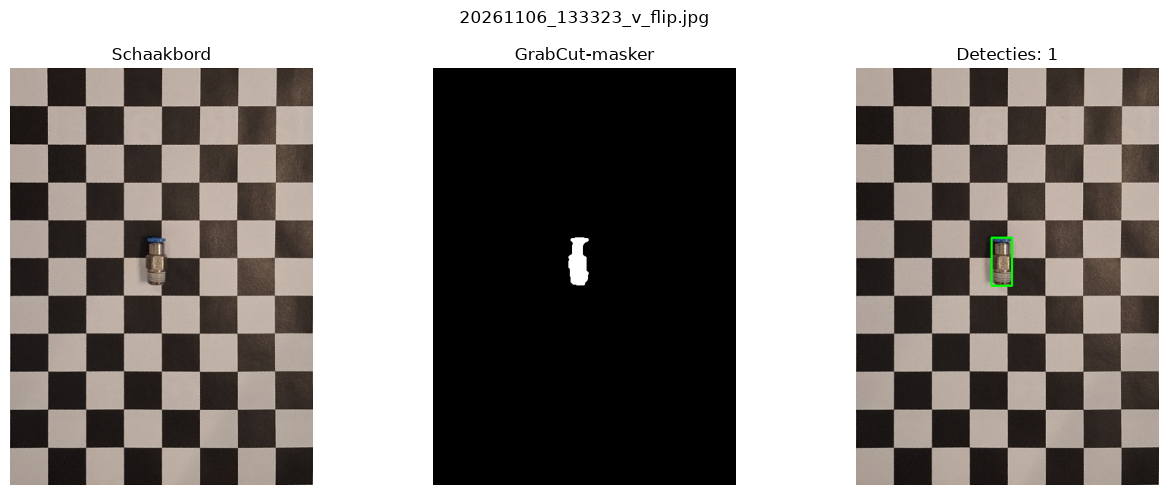

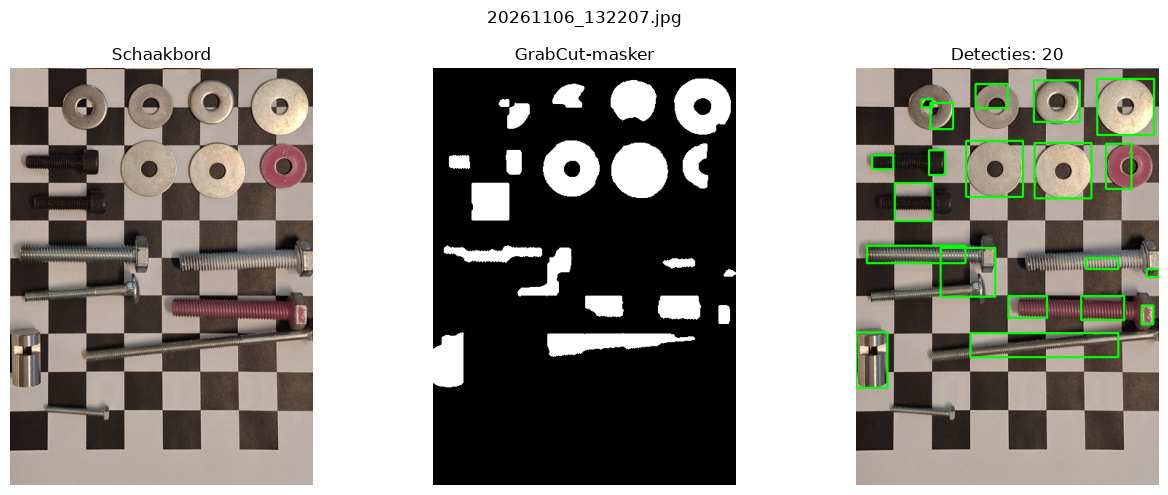

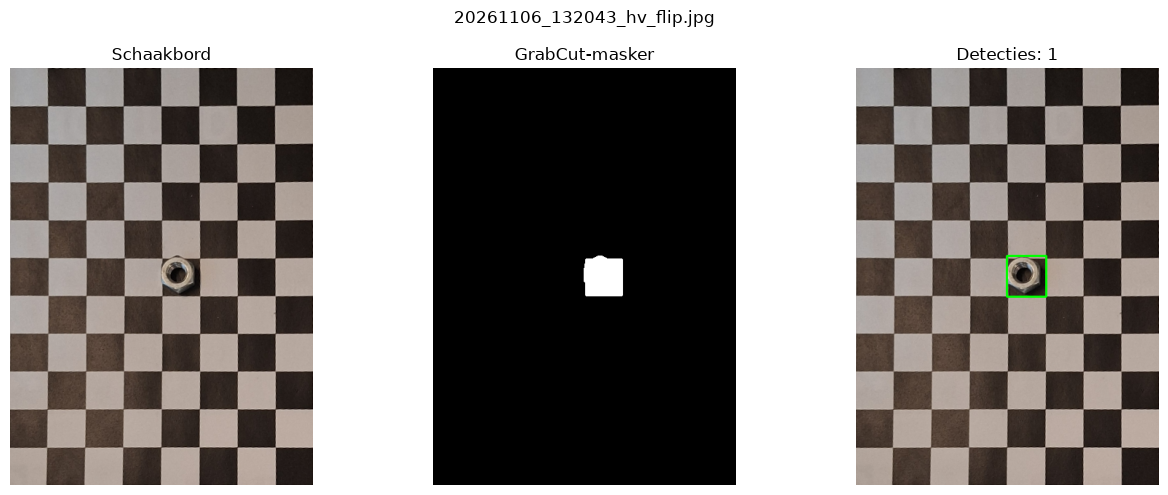

In [5]:
# 5. Test op meerdere foto’s

#BLOK 7

import random

random.seed(42)

MAX_POGINGEN = 20

selectie = random.sample(
    fotos,
    min(MAX_POGINGEN, len(fotos))
)

resultaten = []
overgeslagen = []


for pad in selectie:
    try:
        d = detecteer_op_bord(lees_foto(pad))

        resultaten.append((pad.name, d))

        print(
            f"{pad.name}: {d['methode']} — "
            f"{len(d['detections'])} kandidaten"
        )

    except (
        ValueError,
        RuntimeError,
        cv2.error,
        np.linalg.LinAlgError
    ) as fout:

        overgeslagen.append((pad.name, str(fout)))
        print(f"{pad.name}: overgeslagen — {fout}")

print("\n--- RESULTATEN ---")
print("Geprobeerd:", len(selectie))
print("Succesvol:", len(resultaten))
print("Overgeslagen:", len(overgeslagen))

# Toon maximaal 3 geslaagde voorbeelden
for naam, d in resultaten[:3]:

    fig, assen = plt.subplots(
        1, 3, figsize=(13, 5)
    )

    assen[0].imshow(
        cv2.cvtColor(d["board"], cv2.COLOR_BGR2RGB)
    )
    assen[0].set_title("Schaakbord")

    assen[1].imshow(
        d["mask"], cmap="gray"
    )
    assen[1].set_title("GrabCut-masker")
    
    assen[2].imshow(
        cv2.cvtColor(d["res"], cv2.COLOR_BGR2RGB)
    )
    assen[2].set_title(
        f"Detecties: {len(d['detections'])}"
    )

    for ax in assen:
        ax.axis("off")

    plt.suptitle(naam)
    plt.tight_layout()
    plt.show()


ChessboardCornersSB: Origineel, 100% inliers, rastercontrast 170.5
Afbeelding: 20261106_132207.jpg
Referentie: leeg_schaakbord.jpeg
Uitlijnscore: 19.88
Verschuiving: (0, 0)
Drempel: 58.31
Kandidaatobjecten: 26


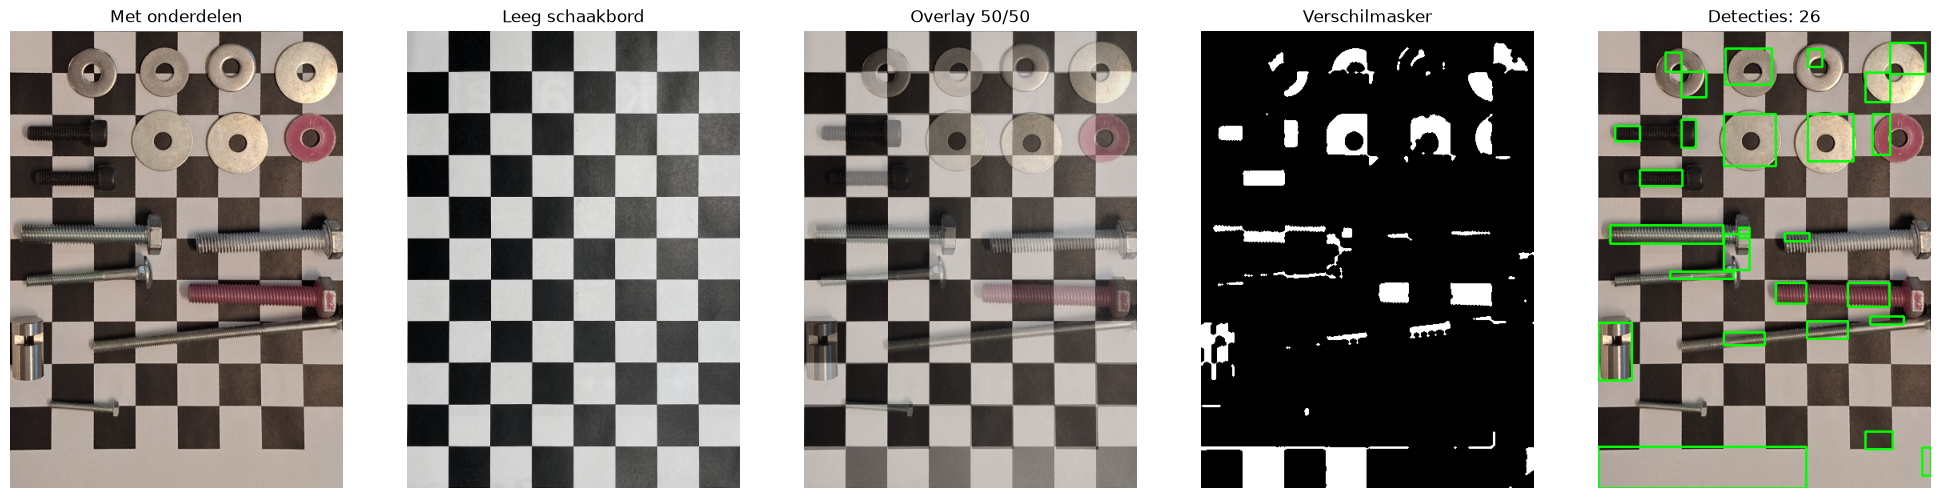

In [6]:
# 6. Referentiefoto vergelijken

# TEST — Echt leeg schaakbord als achtergrond gebruiken
# Geen labels, CNN of YOLO
# Verandert de bestaande detectiecode niet

CELL = 52

# Kies de afbeelding die je wilt testen
NAAM = "20261106_132207.jpg"


# 1. LEGE REFERENTIEFOTO LADEN

paden = [
    Path("leeg_schaakbord.jpeg"),
    Path("images/leeg_schaakbord.jpeg"),
    Path("dataset/images/leeg_schaakbord.jpeg")
]

pad_ref = next((p for p in paden if p.is_file()), None)

if pad_ref is None:
    pad_ref = next(
        (
            p for p in Path(".").rglob("*")
            if p.is_file()
            and p.name.lower() == "leeg_schaakbord.jpeg"
        ),
        None
    )

if pad_ref is None:
    raise FileNotFoundError(
        "leeg_schaakbord.jpeg niet gevonden"
    )

referentie = lees_foto(pad_ref)

# Rechtzetten met onze bestaande ChessboardCornersSB
ref_bord, _, _ = vind_bord_sb(referentie, CELL)


# 2. TESTAFBEELDING OPHALEN

d = next(
    (data for naam, data in resultaten if naam == NAAM),
    None
)

if d is None:
    pad = next(
        (p for p in fotos if p.name == NAAM),
        None
    )

    if pad is None:
        raise FileNotFoundError(NAAM)

    d = detecteer_op_bord(lees_foto(pad))

bord = d["board"].copy()

h, w = bord.shape[:2]


# 3. REFERENTIE UITLIJNEN OP TESTBORD

# Rotaties en spiegelingen proberen.
# Dit is nodig omdat de dataset ook flip-foto's bevat.

varianten = []

for spiegel in [False, True]:

    basis = cv2.flip(ref_bord, 1) if spiegel else ref_bord

    for rotatie in range(4):

        kandidaat = np.ascontiguousarray(
            np.rot90(basis, rotatie)
        )

        if kandidaat.shape[:2] == (h, w):
            varianten.append(kandidaat)

if not varianten:
    raise ValueError(
        "Referentie en testbord hebben verschillende afmetingen"
    )

# Kleine verschuivingen zoeken.
# We beoordelen vooral de pixels die goed overeenkomen,
# zodat de onderdelen niet de hele uitlijning bepalen.

schaal = 4

klein_bord = cv2.resize(
    cv2.cvtColor(bord, cv2.COLOR_BGR2GRAY),
    (w // schaal, h // schaal)
)

def uitlijnscore(a, b):

    delta = np.abs(
        a.astype(np.float32) -
        b.astype(np.float32)
    )

    delta = delta[4:-4, 4:-4].ravel()

    n = int(0.55 * len(delta))

    # Beste 55% van de pixels vergelijken.
    return float(
        np.mean(np.partition(delta, n)[:n])
    )


beste = None

for kandidaat in varianten:

    klein_ref = cv2.resize(
        cv2.cvtColor(kandidaat, cv2.COLOR_BGR2GRAY),
        (w // schaal, h // schaal)
    )

    for dy in range(-3, 4):
        for dx in range(-3, 4):

            M = np.float32([
                [1, 0, dx],
                [0, 1, dy]
            ])

            verschoven = cv2.warpAffine(
                klein_ref,
                M,
                (klein_bord.shape[1], klein_bord.shape[0]),
                borderMode=cv2.BORDER_REFLECT_101
            )

            score = uitlijnscore(
                klein_bord, verschoven
            )

            if beste is None or score < beste[0]:
                beste = (score, kandidaat, dx, dy)

uitlijning, beste_ref, dx, dy = beste

# Gevonden verschuiving terug naar originele resolutie
M = np.float32([
    [1, 0, dx * schaal],
    [0, 1, dy * schaal]
])

ref_uitgelijnd = cv2.warpAffine(
    beste_ref,
    M,
    (w, h),
    borderMode=cv2.BORDER_REFLECT_101
)


# 4. LICHTVERSCHILLEN CORRIGEREN

lab_test = cv2.cvtColor(
    bord, cv2.COLOR_BGR2LAB
).astype(np.float32)

lab_ref = cv2.cvtColor(
    ref_uitgelijnd, cv2.COLOR_BGR2LAB
).astype(np.float32)

ruw = np.mean(
    np.abs(lab_test - lab_ref),
    axis=2
)

# Gebruik het best overeenkomende deel van de foto
achtergrondpixels = ruw <= np.percentile(ruw, 45)

correctie = np.median(
    (lab_test - lab_ref)[achtergrondpixels],
    axis=0
)

lab_ref_corr = np.clip(
    lab_ref + correctie, 0, 255
)

# 5. VERSCHILMASKER MAKEN

delta = np.abs(lab_test - lab_ref_corr)

verschil = (
    0.5 * delta[:, :, 0]
    + 0.25 * delta[:, :, 1]
    + 0.25 * delta[:, :, 2]
)

verschil = cv2.GaussianBlur(
    verschil, (3, 3), 0
)

mediaan = float(np.median(verschil))
mad = float(
    np.median(np.abs(verschil - mediaan))
)

drempel = max(
    20.0,
    mediaan + 5 * 1.4826 * mad
)

masker = np.uint8(
    verschil > drempel
) * 255

masker = cv2.morphologyEx(
    masker,
    cv2.MORPH_OPEN,
    cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (3, 3)
    )
)

masker = cv2.morphologyEx(
    masker,
    cv2.MORPH_CLOSE,
    cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (7, 7)
    )
)


# 6. KANDIDAATOBJECTEN VINDEN

aantal, labels, stats, _ = cv2.connectedComponentsWithStats(
    masker, connectivity=8
)

resultaat = bord.copy()
detecties = []

for i in range(1, aantal):

    x, y, bw, bh, area = map(int, stats[i])

    if area < 100 or min(bw, bh) < 8:
        continue

    if area > 0.20 * w * h:
        continue

    detecties.append((x, y, bw, bh))

    cv2.rectangle(
        resultaat,
        (x, y),
        (x + bw, y + bh),
        (0, 255, 0),
        2
    )


# 7. RESULTATEN TONEN

overlay = cv2.addWeighted(
    bord, 0.5,
    ref_uitgelijnd, 0.5,
    0
)

print("Afbeelding:", NAAM)
print("Referentie:", pad_ref.name)
print("Uitlijnscore:", round(uitlijning, 2))
print("Verschuiving:", (dx*schaal, dy*schaal))
print("Drempel:", round(drempel, 2))
print("Kandidaatobjecten:", len(detecties))

fig, assen = plt.subplots(
    1, 5, figsize=(20, 5)
)

beelden = [
    bord,
    ref_uitgelijnd,
    overlay,
    masker,
    resultaat
]

titels = [
    "Met onderdelen",
    "Leeg schaakbord",
    "Overlay 50/50",
    "Verschilmasker",
    f"Detecties: {len(detecties)}"
]

for ax, beeld, titel in zip(assen, beelden, titels):

    if beeld.ndim == 2:
        ax.imshow(beeld, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(
            cv2.cvtColor(beeld, cv2.COLOR_BGR2RGB)
        )

    ax.set_title(titel)
    ax.axis("off")

plt.tight_layout()
plt.show()


Drempel wit: 32.1
Drempel zwart: 49.6
Nieuwe kandidaatdetecties: 25


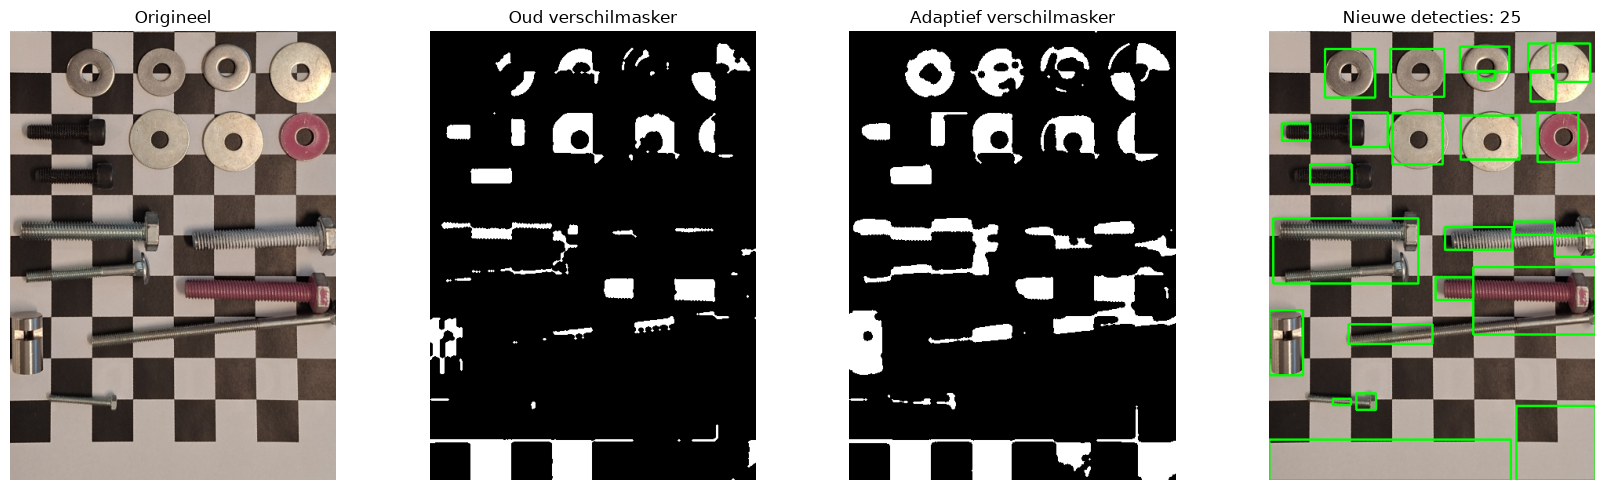

In [7]:
# 7. Adaptieve drempels

# TEST — Verschillende drempels voor zwarte en witte vakjes
# Geen labels, CNN of YOLO

CELL = 52

# 1. ZWARTE EN WITTE VAKJES ONDERSCHEIDEN

grijs_ref = cv2.cvtColor(
    ref_uitgelijnd,
    cv2.COLOR_BGR2GRAY
)

_, witte_vakken = cv2.threshold(
    grijs_ref,
    0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# 2. ADAPTIEVE DREMPELKAART

# Op wit gevoeliger voor kleine verschillen
drempel_wit = max(10.0, drempel * 0.55)

# Op zwart een hogere drempel behouden
drempel_zwart = max(16.0, drempel * 0.85)

drempelkaart = np.where(
    witte_vakken > 0,
    drempel_wit,
    drempel_zwart
).astype(np.float32)

# 3. SCHAAKBORDLIJNEN ONDERDRUKKEN

h, w = verschil.shape
Y, X = np.indices((h, w))

afstand_x = np.minimum(
    X % CELL,
    CELL - 1 - X % CELL
)

afstand_y = np.minimum(
    Y % CELL,
    CELL - 1 - Y % CELL
)

afstand = np.minimum(
    afstand_x, afstand_y
)

# Hogere drempel vlak bij de rasterlijnen
drempelkaart[afstand <= 3] += 12

# 4. NIEUW OBJECTMASKER

masker_nieuw = np.uint8(
    verschil > drempelkaart
) * 255

# Kleine ruis verwijderen
masker_nieuw = cv2.morphologyEx(
    masker_nieuw,
    cv2.MORPH_OPEN,
    cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (3, 3)
    )
)

# Onderbroken objectgebieden verbinden
masker_nieuw = cv2.morphologyEx(
    masker_nieuw,
    cv2.MORPH_CLOSE,
    cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (9, 9)
    )
)

# 5. OBJECTDETECTIE

aantal, labels, stats, _ = (
    cv2.connectedComponentsWithStats(
        masker_nieuw,
        connectivity=8
    )
)

resultaat_nieuw = bord.copy()
detecties_nieuw = []

for i in range(1, aantal):

    x, y, bw, bh, area = map(
        int, stats[i]
    )

    if area < 100 or min(bw, bh) < 8:
        continue

    if area > 0.20 * w * h:
        continue

    detecties_nieuw.append(
        (x, y, bw, bh)
    )

    cv2.rectangle(
        resultaat_nieuw,
        (x, y),
        (x + bw, y + bh),
        (0, 255, 0),
        2
    )

# 6. VERGELIJKING TONEN

print("Drempel wit:", round(drempel_wit, 1))
print("Drempel zwart:", round(drempel_zwart, 1))
print("Nieuwe kandidaatdetecties:", len(detecties_nieuw))

fig, assen = plt.subplots(
    1, 4, figsize=(17, 5)
)

assen[0].imshow(
    cv2.cvtColor(bord, cv2.COLOR_BGR2RGB)
)
assen[0].set_title("Origineel")

assen[1].imshow(
    masker, cmap="gray",
    vmin=0, vmax=255
)
assen[1].set_title("Oud verschilmasker")

assen[2].imshow(
    masker_nieuw, cmap="gray",
    vmin=0, vmax=255
)
assen[2].set_title("Adaptief verschilmasker")

assen[3].imshow(
    cv2.cvtColor(
        resultaat_nieuw, cv2.COLOR_BGR2RGB
    )
)
assen[3].set_title(
    f"Nieuwe detecties: {len(detecties_nieuw)}"
)

for ax in assen:
    ax.axis("off")

plt.tight_layout()
plt.show()


 nummer        klasse  rondheid  verhouding  moment_ratio  solidity  blauw_%   gat  cx  cy
      1      hex_bolt      0.15        5.25          6.36      0.45      0.0 False 340  29
      2      onbekend      0.41        1.11          1.48      0.71      0.0 False 384  34
      3 carriage_bolt      0.17        2.03          2.54      0.48      0.0 False 273  31
      4        washer      0.76        1.05          1.05      0.95      0.0  True 102  53
      5       hex_nut      0.40        1.00          1.14      0.83      0.0  True 189  50
      6 carriage_bolt      0.59        2.22          2.11      0.90      0.0 False 277  54
      7 carriage_bolt      0.69        1.62          1.59      0.94      0.0 False 349  68
      8      onbekend      0.31        1.07          1.81      0.58      0.0 False 114 122
      9 carriage_bolt      0.31        1.68          2.03      0.54      0.0 False 358 136
     10       hex_nut      0.43        1.02          1.04      0.71      0.0  True 183 131

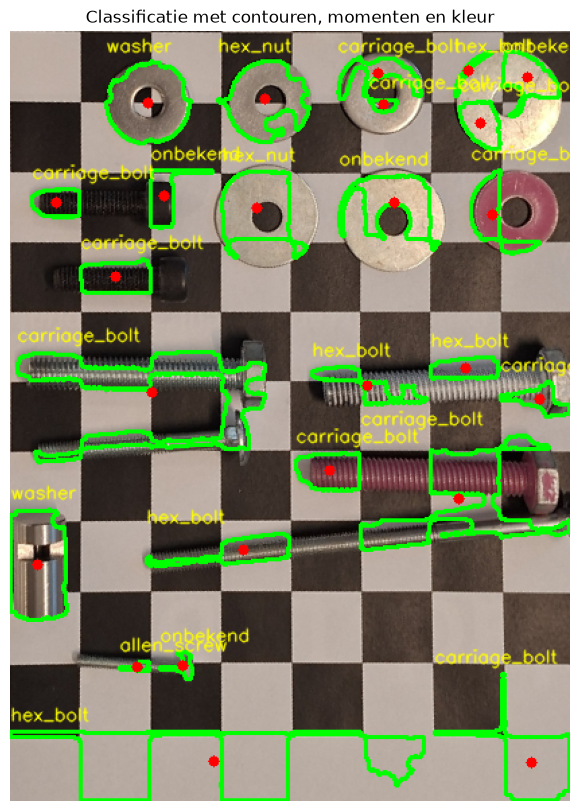

In [8]:
# 8. Classificatie met vorm en kleur

import pandas as pd

CLASSES = (
    "hex_nut",
    "washer",
    "allen_screw",
    "hex_bolt",
    "carriage_bolt",
    "barrel_nut",
    "pneumatic_fitting"
)

resultaat_classificatie = bord.copy()
gegevens = []

# HSV-afbeelding voor kleurherkenning
hsv = cv2.cvtColor(bord, cv2.COLOR_BGR2HSV)

# Blauwe onderdelen herkennen
blauw_masker = cv2.inRange(
    hsv,
    np.array([90, 65, 50]),
    np.array([135, 255, 255])
)

for nummer, (x, y, bw, bh) in enumerate(detecties_nieuw, 1):

    roi = masker_nieuw[y:y+bh, x:x+bw]

    # Contouren bepalen
    contouren, _ = cv2.findContours(
        roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    if not contouren:
        continue

    contour = max(contouren, key=cv2.contourArea)

    oppervlakte = cv2.contourArea(contour)
    omtrek = cv2.arcLength(contour, True)

    if oppervlakte < 20 or omtrek == 0:
        continue

    # 1. Circulariteit
    circulariteit = 4 * np.pi * oppervlakte / (omtrek ** 2)

    # 2. Momenten en zwaartepunt
    M = cv2.moments(contour)

    if M["m00"] == 0:
        continue

    cx = x + int(M["m10"] / M["m00"])
    cy = y + int(M["m01"] / M["m00"])

    # 3. Vormverhouding
    rect = cv2.minAreaRect(contour)
    (_, _), (rw, rh), hoek = rect

    verhouding = max(rw, rh) / max(1, min(rw, rh))

    # 4. Solidity: hoe goed vult de contour zijn convexe omhulling?
    hull = cv2.convexHull(contour)
    hull_area = cv2.contourArea(hull)
    solidity = oppervlakte / hull_area if hull_area > 0 else 0

    # 5. Gatdetectie via contourhiërarchie
    contouren_gat, hierarchie = cv2.findContours(
        roi, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE
    )

    gat_oppervlakte = 0

    if hierarchie is not None:
        for i, h in enumerate(hierarchie[0]):
            if h[3] != -1:
                gat_oppervlakte += cv2.contourArea(contouren_gat[i])

    heeft_gat = gat_oppervlakte > 30

    # 6. Blauwpercentage binnen de contour
    object_masker = np.zeros((bh, bw), dtype=np.uint8)
    cv2.drawContours(object_masker, [contour], -1, 255, -1)

    blauw_roi = blauw_masker[y:y+bh, x:x+bw]

    blauwe_pixels = np.count_nonzero(
        (blauw_roi > 0) & (object_masker > 0)
    )
    object_pixels = np.count_nonzero(object_masker)

    blauw_ratio = blauwe_pixels / max(1, object_pixels)

    # 7. Vormmomenten: spreiding rond het zwaartepunt
    mu20 = M["mu20"] / M["m00"]
    mu02 = M["mu02"] / M["m00"]
    mu11 = M["mu11"] / M["m00"]

    cov = np.array([
        [mu20, mu11],
        [mu11, mu02]
    ])

    eigenwaarden = np.linalg.eigvalsh(cov)
    moment_ratio = np.sqrt(
        max(eigenwaarden[-1], 0) /
        max(eigenwaarden[0], 1e-6)
    )

    # ==========================================
    # CLASSIFICATIE
    # ==========================================

    if blauw_ratio > 0.04 and verhouding < 2.5:
        klasse = "pneumatic_fitting"

    elif heeft_gat and circulariteit > 0.65:
        klasse = "washer"

    elif heeft_gat and verhouding < 1.6:
        klasse = "hex_nut"

    elif verhouding > 3.5 or moment_ratio > 3.5:
        klasse = "hex_bolt"

    elif verhouding > 2.3:
        klasse = "allen_screw"

    elif circulariteit > 0.75 and solidity > 0.9:
        klasse = "barrel_nut"

    elif verhouding > 1.5:
        klasse = "carriage_bolt"

    else:
        klasse = "onbekend"

    # Contour tekenen op de originele afbeelding
    contour_globaal = contour + np.array([[[x, y]]])

    cv2.drawContours(
        resultaat_classificatie,
        [contour_globaal],
        -1, (0, 255, 0), 2
    )

    # Zwaartepunt tekenen
    cv2.circle(
        resultaat_classificatie,
        (cx, cy), 4, (0, 0, 255), -1
    )

    # Naam boven het onderdeel
    cv2.putText(
        resultaat_classificatie,
        klasse,
        (x, max(15, y - 8)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.45, (0, 255, 255), 1, cv2.LINE_AA
    )

    gegevens.append({
        "nummer": nummer,
        "klasse": klasse,
        "rondheid": round(circulariteit, 2),
        "verhouding": round(verhouding, 2),
        "moment_ratio": round(moment_ratio, 2),
        "solidity": round(solidity, 2),
        "blauw_%": round(blauw_ratio * 100, 1),
        "gat": heeft_gat,
        "cx": cx,
        "cy": cy
    })

df = pd.DataFrame(gegevens)

print(df.to_string(index=False))

plt.figure(figsize=(14, 10))
plt.imshow(cv2.cvtColor(resultaat_classificatie, cv2.COLOR_BGR2RGB))
plt.title("Classificatie met contouren, momenten en kleur")
plt.axis("off")
plt.show()
